## **EventIQ: Revenue and Ticket Types Exploratory Analysis**

This notebook presents an **Exploratory Data Analysis (EDA)** of the **EventIQ** platform, connecting directly to the shared Oracle database to evaluate business logic patterns and ticket purchasing behaviors defined by the data generator.

**Main Objectives:**
* **Revenue Analysis:** Examine total earnings per **event**, counting only paid tickets.
* **Ticket Mix Distribution:** Compare sales and revenue across **ticket types (General, VIP, Student)**.
* **Data-Driven Insights:** Provide **key findings** based on the data and business logic.

### 1. Data Loading and Database Connection

In [2]:
import sys
import os

import pandas as pd
import matplotlib.pyplot as plt

In [3]:
sys.path.append(os.path.abspath("../analytics-service"))

In [4]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, PINK, GREEN, GREY = "#5AC2FF", "#EC6AA5", "#5FDE4B", "#b5bac1"
TYPE_COLORS = {"Student": GREEN, "General": BLUE, "VIP": PINK}

In [22]:
from database import query_to_dataframe
from eda import REVENUE_BY_EVENT_SQL, TICKET_TYPE_DISTRIBUTION_SQL

 Load the data in database from pandas

In [7]:
revenue = query_to_dataframe(REVENUE_BY_EVENT_SQL)
revenue.head()

/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


,event_id,name,event_date,capacity,tickets_sold,revenue
0,99,DevSummit Latam,2027-04-09,30000,39,26650
1,81,Exposición de Diseño y Creatividad,2027-09-02,30000,37,24500
2,29,Congreso de Ingeniería de Software,2027-02-06,30000,44,24000
3,71,Foro de Emprendimiento e Innovación,2027-04-15,50000,55,23500
4,68,Expo Cerveza Artesanal,2027-01-05,30000,39,22800


In [8]:
tickets = query_to_dataframe(TICKET_TYPE_DISTRIBUTION_SQL)
tickets.head()

/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


,ticket_type,tickets,revenue
0,Student,440,28050
1,VIP,434,370500
2,General,407,72500
3,Postman General,0,0


In [9]:
checks = {
    "payments whose amount differs from their ticket price": query_to_dataframe(
        "SELECT COUNT(*) AS n FROM payments p JOIN ticket_types t ON t.ticket_type_id = p.ticket_type_id "
        "WHERE p.amount <> t.price"
    )["n"][0],
    "events without ticket types": query_to_dataframe(
        "SELECT COUNT(*) AS n FROM events e WHERE NOT EXISTS (SELECT 1 FROM ticket_types t WHERE t.event_id = e.event_id)"
    )["n"][0],
    "registrations without exactly one payment": query_to_dataframe(
        "SELECT COUNT(*) AS n FROM (SELECT r.registration_id FROM registrations r "
        "LEFT JOIN payments p ON p.registration_id = r.registration_id "
        "GROUP BY r.registration_id HAVING COUNT(p.payment_id) <> 1)"
    )["n"][0],
}
pd.Series(checks, name="rows").to_frame()

/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


,rows
payments whose amount differs from their ticket price,0
events without ticket types,6
registrations without exactly one payment,0


***Events without ticket types:***

In [10]:
query_to_dataframe(
    "SELECT e.event_id, e.name FROM events e "
    "WHERE NOT EXISTS (SELECT 1 FROM ticket_types t WHERE t.event_id = e.event_id)"
)

/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


,event_id,name
0,222,Java Day
1,223,Java Day
2,224,Java Day
3,225,Java Day
4,226,Java Day
5,221,Java Day


***The 6 events without ticket types are test events***

### 2. Exploratory Analysis of Revenue by Event

##### **2.1. Total Revenue per Event**

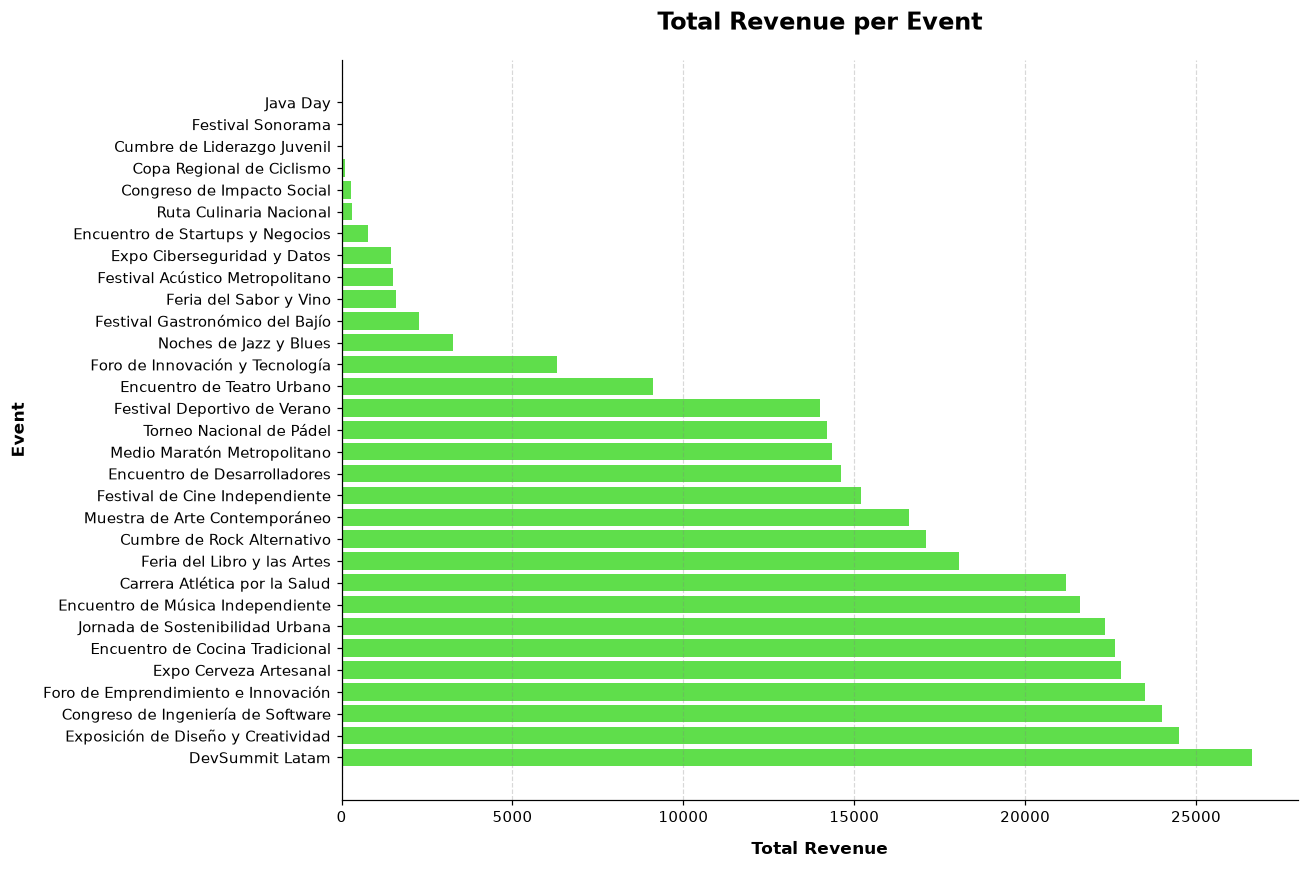

In [11]:
revenue_sorted = revenue.sort_values(by="revenue", ascending=False)
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    revenue_sorted["name"],
    revenue_sorted["revenue"],
    color=GREEN,
    linewidth=0.5,
)

ax.set_title("Total Revenue per Event", fontsize=16, fontweight="bold", pad=20, color="black")
ax.set_xlabel("Total Revenue", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("Event", fontsize=11, fontweight="bold", labelpad=10)

ax.grid(axis="x", linestyle="--", alpha=0.3, color="gray")

plt.tight_layout()
plt.show()

##### **2.2. Frequency Distribution of Revenue**

In [ ]:
revenue = query_to_dataframe(REVENUE_BY_EVENT_SQL).sort_values("revenue", ascending=False).reset_index(drop=True)

total_revenue = revenue["revenue"].sum()
revenue["share"] = (revenue["revenue"] / total_revenue).round(3)
revenue["cumulative_share"] = revenue["share"].cumsum().round(3)

print(f"Total revenue: {total_revenue:,.0f} from {len(revenue)} events")
print(f"Events with no revenue: {(revenue['revenue'] == 0).sum()}")
print(f"Median event: {revenue['revenue'].median():,.0f}   Mean event: {revenue['revenue'].mean():,.0f}   Best event: {revenue['revenue'].max():,.0f}")

# Mostrar el Top 10
revenue.head(10)

Total revenue: 471,050 from 106 events
Events with no revenue: 33
Median event: 400   Mean event: 4,444   Best event: 26,650


/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


,event_id,name,event_date,capacity,tickets_sold,revenue,share,cumulative_share
0,99,DevSummit Latam,2027-04-09,30000,39,26650,0.057,0.057
1,81,Exposición de Diseño y Creatividad,2027-09-02,30000,37,24500,0.052,0.109
2,29,Congreso de Ingeniería de Software,2027-02-06,30000,44,24000,0.051,0.160
3,71,Foro de Emprendimiento e Innovación,2027-04-15,50000,55,23500,0.050,0.210
4,68,Expo Cerveza Artesanal,2027-01-05,30000,39,22800,0.048,0.258
5,21,Congreso de Ingeniería de Software,2027-11-24,30000,39,22650,0.048,0.306
6,48,Encuentro de Cocina Tradicional,2027-12-08,30000,39,22625,0.048,0.354
7,26,Jornada de Sostenibilidad Urbana,2027-08-13,30000,38,22350,0.047,0.401
8,3,Encuentro de Música Independiente,2027-09-16,50000,68,21600,0.046,0.447
9,79,Carrera Atlética por la Salud,2027-06-01,50000,67,21200,0.045,0.492


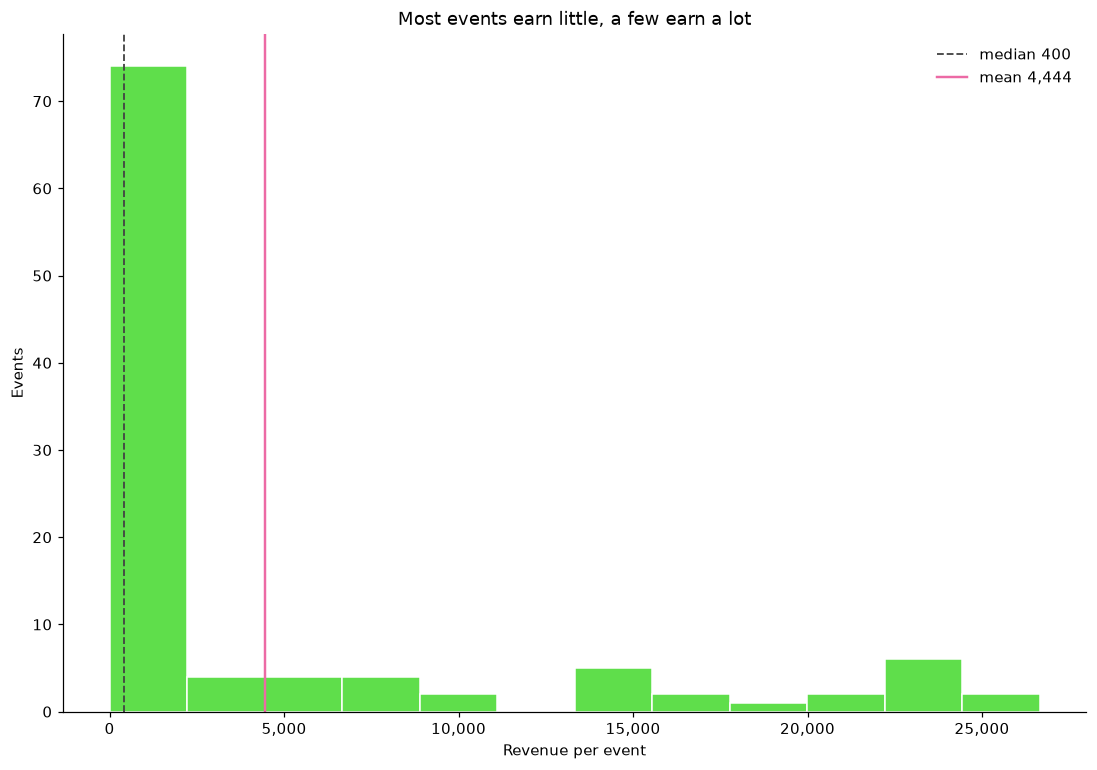

In [20]:
top5 = revenue["revenue"].head(5).sum() / total_revenue
top10 = revenue["revenue"].head(10).sum() / total_revenue

fig, ax = plt.subplots(figsize=(12, 8))

ax.hist(revenue["revenue"], bins=12, color=GREEN, edgecolor="white")
ax.axvline(revenue["revenue"].median(), color="#444", ls="--", lw=1.2, label=f"median {revenue['revenue'].median():,.0f}")
ax.axvline(revenue["revenue"].mean(), color=PINK, lw=1.6, label=f"mean {revenue['revenue'].mean():,.0f}")
ax.set(title="Most events earn little, a few earn a lot", xlabel="Revenue per event", ylabel="Events")
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.legend(frameon=False)

##### **2.3. Top 5 Events by Revenue**

In [30]:
revenue_top10 = revenue_sorted.head(10)
revenue_top10

,event_id,name,event_date,capacity,tickets_sold,revenue
0,99,DevSummit Latam,2027-04-09,30000,39,26650
1,81,Exposición de Diseño y Creatividad,2027-09-02,30000,37,24500
2,29,Congreso de Ingeniería de Software,2027-02-06,30000,44,24000
3,71,Foro de Emprendimiento e Innovación,2027-04-15,50000,55,23500
4,68,Expo Cerveza Artesanal,2027-01-05,30000,39,22800
5,21,Congreso de Ingeniería de Software,2027-11-24,30000,39,22650
6,48,Encuentro de Cocina Tradicional,2027-12-08,30000,39,22625
7,26,Jornada de Sostenibilidad Urbana,2027-08-13,30000,38,22350
8,3,Encuentro de Música Independiente,2027-09-16,50000,68,21600
9,79,Carrera Atlética por la Salud,2027-06-01,50000,67,21200


##### **2.4. Bottom 5 Events by Revenue**

In [31]:
revenue_bottom10 = revenue_sorted.tail(10)
revenue_bottom10

,event_id,name,event_date,capacity,tickets_sold,revenue
96,222,Java Day,2027-11-20,1000,0,0
97,223,Java Day,2027-11-20,1000,0,0
98,224,Java Day,2027-11-20,1000,0,0
99,225,Java Day,2027-11-20,1000,0,0
100,226,Java Day,2027-11-20,1000,0,0
101,54,Medio Maratón Metropolitano,2027-08-02,250,1,0
102,20,Muestra de Arte Contemporáneo,2027-01-02,1500,2,0
103,35,Muestra de Arte Contemporáneo,2027-08-15,30000,37,0
104,61,Noches de Jazz y Blues,2027-03-24,250,1,0
105,84,Torneo Nacional de Pádel,2027-10-30,1000,2,0


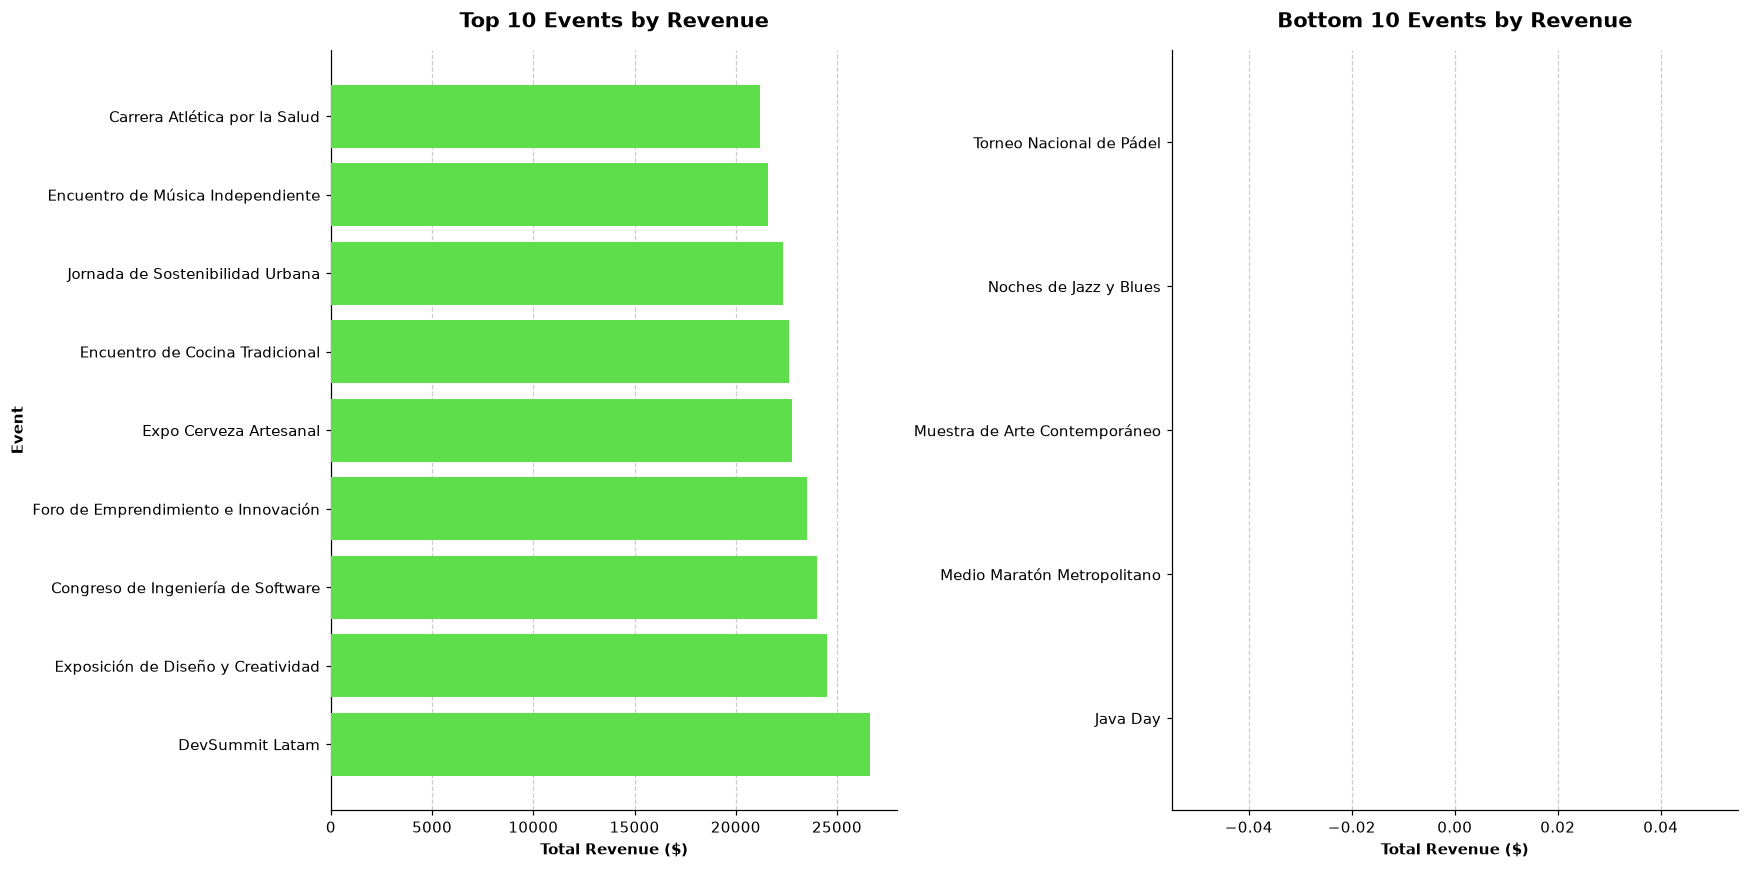

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharex=False)

ax1.barh(
    revenue_top10["name"],
    revenue_top10["revenue"],
    color=GREEN,
    edgecolor="none",
    zorder=3,
)
ax1.grid(axis="x", linestyle="--", alpha=0.4, color="gray", zorder=1)
ax1.set_title("Top 10 Events by Revenue", fontsize=14, fontweight="bold", pad=15, color="black")
ax1.set_xlabel("Total Revenue ($)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Event", fontsize=10, fontweight="bold")

ax2.barh(
    revenue_bottom10["name"],
    revenue_bottom10["revenue"],
    color=BLUE, 
    edgecolor="none",
    zorder=3,
)
ax2.grid(axis="x", linestyle="--", alpha=0.4, color="gray", zorder=1)
ax2.set_title("Bottom 10 Events by Revenue", fontsize=14, fontweight="bold", pad=15, color="black")
ax2.set_xlabel("Total Revenue ($)", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

### 3. Exploratory Analysis of Ticket Type Distribution

In [42]:
import eda

mix = eda.ticket_type_distribution_df().set_index("ticket_type").reindex(["Student", "General", "VIP"])
mix["avg_paid_price"] = (mix["revenue"] / mix["tickets"]).round(1)
mix

,tickets,revenue,ticket_share,revenue_share,avg_paid_price
ticket_type,,,,,
Student,440,28050,0.3435,0.0595,63.8
General,407,72500,0.3177,0.1539,178.1
VIP,434,370500,0.3388,0.7865,853.7


In [43]:
list_prices = query_to_dataframe("SELECT name AS ticket_type, price FROM ticket_types")

/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


#### **3.1 Ticket Volume Share Distribution**

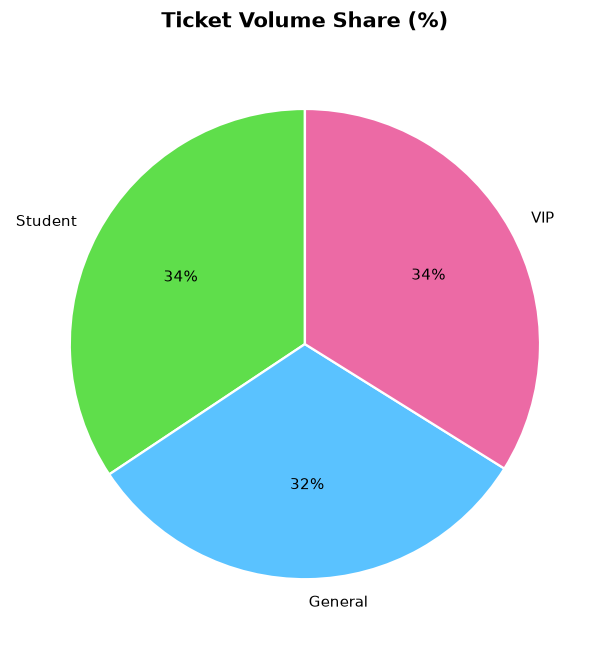

In [44]:
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, autotexts = ax.pie(
    mix["ticket_share"], 
    labels=mix.index, 
    autopct='%1.0f%%', 
    startangle=90, 
    colors=TYPE_COLORS.values(), 
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

ax.set_title("Ticket Volume Share (%)", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

#### **3.2 Price Dispersion and Value Behavior**

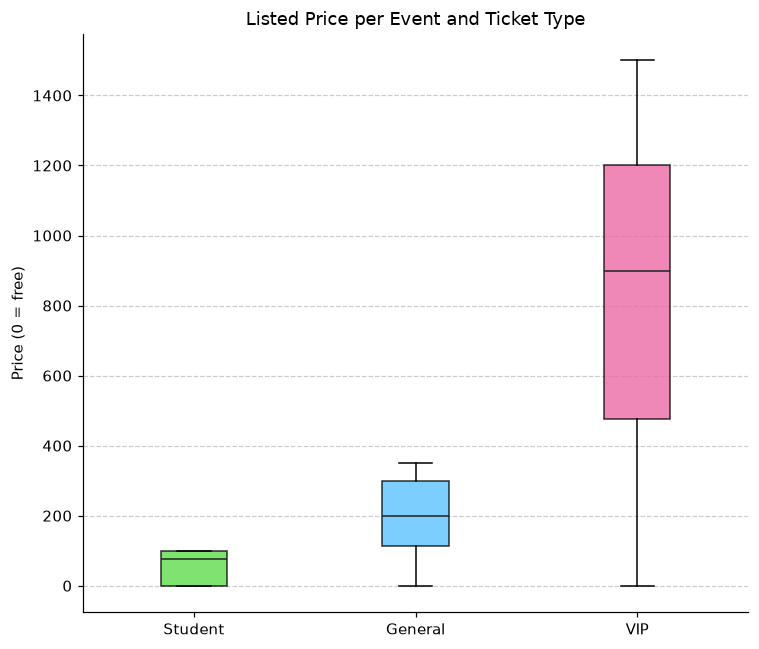

In [45]:
fig, ax = plt.subplots(figsize=(7, 6))

data = [list_prices.loc[list_prices["ticket_type"] == t, "price"] for t in mix.index]
box = ax.boxplot(data, tick_labels=list(mix.index), patch_artist=True, medianprops={"color": "#222"})

for patch, t in zip(box["boxes"], mix.index):
    patch.set_facecolor(TYPE_COLORS.get(t, BLUE))
    patch.set_alpha(0.8)

ax.set(title="Listed Price per Event and Ticket Type", ylabel="Price (0 = free)")
ax.grid(axis="y", linestyle="--", alpha=0.4, color="gray", zorder=1)

plt.tight_layout()
plt.show()

#### **3.3 Payment Status**

In [50]:
status = query_to_dataframe("SELECT status, COUNT(*) AS n_payments, SUM(amount) AS amount FROM payments GROUP BY status")
status = status.set_index("status").reindex(["paid", "pending", "refunded"])
status["payments_share"] = (status["n_payments"] / status["n_payments"].sum()).round(3)
status["amount_share"] = (status["amount"] / status["amount"].sum()).round(3)
status

/home/gianina/projects/event-iq/analytics-service/database.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)  # pandas warns that it prefers SQLAlchemy; harmless here


,n_payments,amount,payments_share,amount_share
status,,,,
paid,1281,471050,0.801,0.804
pending,160,51375,0.100,0.088
refunded,159,63350,0.099,0.108


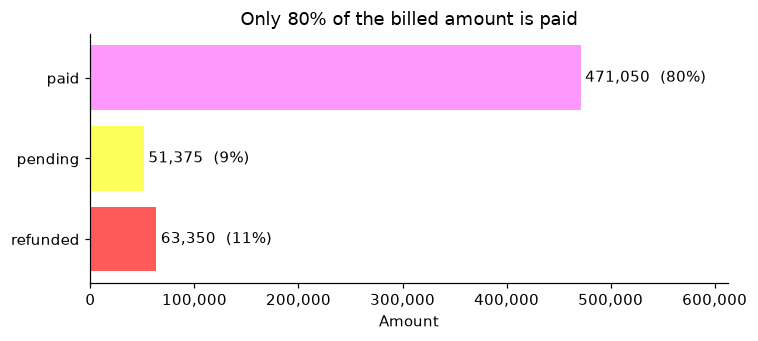

In [51]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(status.index[::-1], status["amount"][::-1], color=["#FF5A5A", "#FFFF5A", "#FF98FC"])
ax.bar_label(bars, labels=[f"{v:,.0f}  ({s:.0%})" for v, s in zip(status["amount"][::-1], status["amount_share"][::-1])], padding=3)
ax.set(title=f"Only {status.loc['paid', 'amount_share']:.0%} of the billed amount is paid", xlabel="Amount", xlim=(0, status["amount"].max() * 1.3))
ax.xaxis.set_major_formatter("{x:,.0f}")
fig.tight_layout()
plt.show()

### 4. Key Findings

* **1. Ticket Volume vs. Pricing Split:** While the number of tickets sold is almost evenly split between Student (34%), VIP (34%), and General (32%) categories, VIP tickets are significantly more expensive, reaching up to $1,500 with a median price of 900.
* **2. Highly Skewed Revenue Across Events:** Event income is unevenly distributed, with a low median revenue of 400 compared to a much higher average of 4,444. This shows that a few top events bring in most of the money while most earn very little.
* **3. Top Revenue Driver:** *DevSummit Latam* is the single highest-earning event, generating over $25,000 in total revenue and outperforming all other listed events.
* **4. Solid Paid Transaction Rate:** **80% ($471,050)** of all billed amounts have been successfully paid and collected.
* **5. Uncollected Revenue Breakdown:** The remaining **20%** of total billed money is currently uncollected, divided into **11% ($63,350) in refunds** and **9% ($51,375) in pending payments**.